# 04 · Customer Lifetime Value (BG/NBD + Gamma-Gamma)

**Goal:** predict how much each customer will spend in the next 12 months.

RFM and clustering describe the past; CLV is a forecast. It tells the business how much it is worth
spending to keep or win back a customer. It is computed as

**CLV = expected number of purchases × expected value per purchase**, discounted over time,

with one model for each part:

- **BG/NBD** predicts the number of purchases. While a customer is "alive" they buy at their own
  rate; after every purchase they may leave for good, which is never observed directly. Silence is
  judged relative to each customer's own rhythm.
- **Gamma-Gamma** predicts the value per purchase, pulling the average of customers with few purchases
  towards the overall average.

CLV here is in **revenue**, not profit: product margins are not in the data.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifetimes import BetaGeoFitter, ModifiedBetaGeoFitter

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src import clv

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# lifetimes is no longer maintained and raises pandas deprecation warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

transactions = pd.read_parquet(PROCESSED_DIR / "transactions.parquet")
returns = pd.read_parquet(PROCESSED_DIR / "returns.parquet")
segments = pd.read_parquet(PROCESSED_DIR / "segments.parquet")

END = transactions["invoice_date"].max().normalize()
print(f"Data ends on {END:%Y-%m-%d}")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def style_axis(ax):
    """Light, recessive axes so the data stands out."""
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

Data ends on 2011-12-09


## From transactions to model inputs

BG/NBD counts purchase *occasions*, so the data is first reduced to one row per customer and day:
two invoices from the same customer on the same day count as one purchase.

Revenue is gross of returns. Gamma-Gamma only accepts positive values, and the unpaired returns from
phase 1 are a negligible share of revenue:

In [2]:
daily = clv.daily_purchases(transactions)

invoices_per_customer = transactions.groupby("customer_id")["invoice"].nunique()
days_per_customer = daily.groupby("customer_id").size()
print(f"Customers with several invoices on the same day: {(invoices_per_customer > days_per_customer).sum():,}")
print(f"Unpaired returns as a share of gross revenue: {-returns['revenue'].sum() / transactions['revenue'].sum():.1%}")

Customers with several invoices on the same day: 1,198


Unpaired returns as a share of gross revenue: 1.0%


Each customer is summarised by four numbers. Time is measured in **weeks**: the models give the same
predictions in days, but the optimiser is better conditioned with smaller numbers.

- **frequency**: number of *repeat* purchase days (the first purchase is not counted)
- **recency**: customer age at the last purchase, i.e. weeks from the first to the last purchase
- **T**: customer age today, i.e. weeks from the first purchase to the end of the data
- **monetary_value**: average value of the repeat purchase days

⚠️ **Recency here is not the RFM recency.** In RFM it was days *since* the last purchase; in BG/NBD it is
the time *between* the first and the last purchase. A customer who bought only once has recency 0.

In [3]:
summary = clv.customer_summary(daily, END)

examples = [14911, 17850, 13902, 12367]
summary.loc[examples].round(1)

,frequency,recency,T,monetary_value
customer_id,,,,
14911,244.0,105.3,105.4,1062.2
17850,22.0,51.7,104.9,2217.7
13902,4.0,13.1,103.4,7508.7
12367,0.0,0.0,0.6,0.0


Customer 17850 bought on 23 different days (frequency 22) and was still buying regularly at week 52 of
their life, but is now 104 weeks old: almost a year of silence for a customer who used to buy every
couple of weeks. Customer 12367 has bought once, so frequency and recency are both 0.

## Validation design: calibration and holdout

To check the model before trusting it, it is fitted on the first 18 months only (**calibration**:
Dec 2009 – 9 Jun 2011) and its predictions are compared with what customers actually did in the last
6 months (**holdout**: 10 Jun – 9 Dec 2011). Only customers who had already bought in the calibration
period can be evaluated.

In [4]:
CALIBRATION_END = pd.Timestamp("2011-06-09")

ch = clv.calibration_holdout(daily, CALIBRATION_END, END)
horizon = ch["duration_holdout"].iloc[0]
f, r, T = ch["frequency_cal"], ch["recency_cal"], ch["T_cal"]
actual = ch["frequency_holdout"]

print(f"{len(ch):,} customers in calibration, holdout of {horizon:.1f} weeks, "
      f"{actual.sum():,.0f} actual repeat purchases in the holdout")

4,935 customers in calibration, holdout of 26.1 weeks, 7,720 actual repeat purchases in the holdout


Why not a symmetric 12 + 12 months split, which would put one Christmas in each period? With only one
year of history the model cannot tell slow buyers from customers who have left:

In [5]:
ch_1y = clv.calibration_holdout(daily, pd.Timestamp("2010-12-09"), END)
bg_1y = clv.fit_bgnbd(ch_1y["frequency_cal"], ch_1y["recency_cal"], ch_1y["T_cal"])
pred_1y = bg_1y.conditional_expected_number_of_purchases_up_to_time(
    ch_1y["duration_holdout"].iloc[0], ch_1y["frequency_cal"], ch_1y["recency_cal"], ch_1y["T_cal"])

print("Parameters with 12 months of calibration:", bg_1y.params_.round(3).to_dict())
print(f"Predicted {pred_1y.sum():,.0f} purchases vs {ch_1y['frequency_holdout'].sum():,.0f} actual "
      f"({pred_1y.sum() / ch_1y['frequency_holdout'].sum() - 1:+.0%})")

Parameters with 12 months of calibration: {'r': 0.888, 'alpha': 10.406, 'a': 0.157, 'b': 89.999}
Predicted 18,626 purchases vs 12,123 actual (+54%)


The dropout parameter `b` ends up at about 90, the edge of what the optimiser can reach, and the model
overestimates future purchases by more than half: it has not seen enough silence to learn how customers
leave. With 18 months of calibration the parameters are reasonable, so that split is used.

## BG/NBD: number of purchases

The model is compared with a **naive baseline**: every customer keeps buying at the repeat-purchase rate
observed so far. It is the simplest forecast a business would make, and a model that cannot beat it is
not worth its complexity.

In [6]:
bgf = clv.fit_bgnbd(f, r, T)
print("BG/NBD parameters:", bgf.params_.round(3).to_dict())

predicted = bgf.conditional_expected_number_of_purchases_up_to_time(horizon, f, r, T)
naive = clv.naive_purchases(f, T, horizon)

weeks_silent = T - r
group = pd.Series(np.select(
    [f == 0, weeks_silent > 26], ["One purchase only", "Repeat, silent > 6 months"], "Repeat, active"
), index=ch.index)

def evaluate(mask):
    return pd.Series({
        "customers": mask.sum(),
        "actual": actual[mask].sum(),
        "bgnbd": predicted[mask].sum(),
        "naive": naive[mask].sum(),
        "mae_bgnbd": (predicted - actual)[mask].abs().mean(),
        "mae_naive": (naive - actual)[mask].abs().mean(),
    })

results = pd.DataFrame({g: evaluate(group == g) for g in group.unique()}).T
results.loc["All customers"] = evaluate(pd.Series(True, index=ch.index))
results.style.format({"customers": "{:,.0f}", "actual": "{:,.0f}", "bgnbd": "{:,.0f}", "naive": "{:,.0f}",
                      "mae_bgnbd": "{:.2f}", "mae_naive": "{:.2f}"})

BG/NBD parameters: {'r': 0.684, 'alpha': 9.549, 'a': 0.148, 'b': 3.199}


,customers,actual,bgnbd,naive,mae_bgnbd,mae_naive
"Repeat, silent > 6 months","1,122",763,810,"1,091",0.77,0.95
"Repeat, active","2,205","6,232","5,984","6,993",1.49,1.62
One purchase only,"1,608",725,812,0,0.62,0.45
All customers,"4,935","7,720","7,606","8,084",1.04,1.09


In [7]:
print(f"Rank correlation with actual purchases (Spearman): "
      f"BG/NBD {predicted.corr(actual, method='spearman'):.3f}, naive {naive.corr(actual, method='spearman'):.3f}")

Rank correlation with actual purchases (Spearman): BG/NBD 0.624, naive 0.575


An honest reading of the results:

- **Per customer, BG/NBD is only slightly better than the baseline** (lower MAE overall). The naive rate
  is a strong baseline for customers who are still active.
- **It is much better on the hard cases.** The baseline assumes customers silent for months keep buying
  at their old rate, and that one-time buyers will never buy again. BG/NBD gets both groups roughly right.
- **In total**, BG/NBD is within a few percent of the actual number of purchases.

The chart groups customers by how many repeat purchases they made in calibration and compares the
average number of purchases in the holdout:

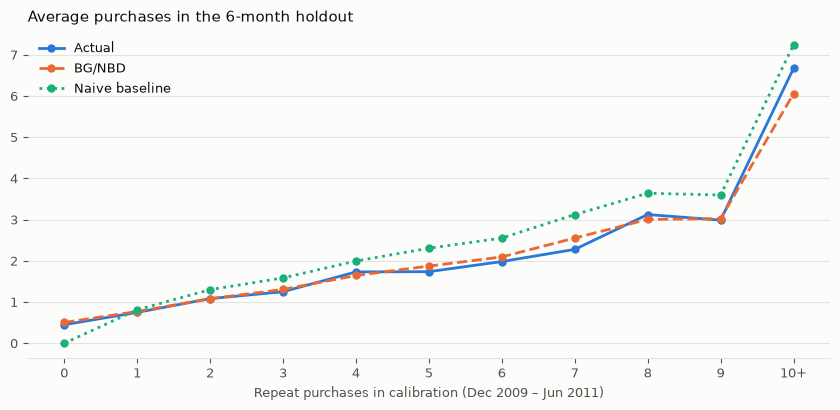

In [8]:
bucket = f.clip(upper=10).astype(int)
by_bucket = pd.DataFrame({"Actual": actual, "BG/NBD": predicted, "Naive baseline": naive}).groupby(bucket).mean()

fig, ax = plt.subplots(figsize=(8.5, 4.2), facecolor=SURFACE)
for col, color, style in [("Actual", BLUE, "-"), ("BG/NBD", ORANGE, "--"), ("Naive baseline", AQUA, ":")]:
    ax.plot(by_bucket.index, by_bucket[col], color=color, linestyle=style, linewidth=2,
            marker="o", markersize=5, label=col)
ax.set_xticks(by_bucket.index, [str(i) for i in by_bucket.index[:-1]] + ["10+"])
ax.set_xlabel("Repeat purchases in calibration (Dec 2009 – Jun 2011)", color=MUTED, fontsize=9)
ax.set_title("Average purchases in the 6-month holdout", loc="left", color=TEXT, fontsize=11)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.legend(frameon=False, fontsize=9, labelcolor=TEXT)
style_axis(ax)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_holdout_purchases.png", dpi=150, facecolor=SURFACE)
plt.show()

### A known limitation: one-time buyers

In BG/NBD a customer can only leave right after a *repeat* purchase. A customer who bought once is
therefore considered alive with probability 1, however long ago that purchase was. The modified BG/NBD
(MBG/NBD) also allows leaving after the first purchase. Comparing the two:

In [9]:
one_time = f == 0
rows = {}
for name, model in [("BG/NBD", BetaGeoFitter), ("MBG/NBD", ModifiedBetaGeoFitter)]:
    fitted = clv.fit_bgnbd(f, r, T, model=model)
    pred = fitted.conditional_expected_number_of_purchases_up_to_time(horizon, f, r, T)
    p_alive = pd.Series(fitted.conditional_probability_alive(f, r, T), index=ch.index)
    rows[name] = {
        "mae": (pred - actual).abs().mean(),
        "predicted_total": pred.sum(),
        "median_p_alive_one_time_buyers": p_alive[one_time].median(),
    }
rows = pd.DataFrame(rows).T
rows

,mae,predicted_total,median_p_alive_one_time_buyers
BG/NBD,1.043405,7605.798065,1.000000
MBG/NBD,1.046689,7633.470383,0.902349


In [10]:
print(f"One-time buyers in calibration who bought again in the holdout: {(actual[one_time] > 0).mean():.1%}")

One-time buyers in calibration who bought again in the holdout: 26.6%


Both models are equally accurate on the number of purchases. MBG/NBD gives more realistic
probabilities of being alive for one-time buyers, but those probabilities are still high. BG/NBD is kept,
and **P(alive) is not used for one-time buyers**: for them the model knows very little.

## Gamma-Gamma: value per purchase

Gamma-Gamma assumes that the value of a customer's purchases does not depend on how often they buy.
This can be checked on the repeat customers:

In [11]:
repeat = ch[ch["frequency_cal"] > 0]
print(f"Correlation between frequency and average purchase value: "
      f"{repeat['frequency_cal'].corr(repeat['monetary_value_cal']):.2f}")

Correlation between frequency and average purchase value: 0.13


The correlation is weak, so the assumption is acceptable.

In [12]:
ggf = clv.fit_gamma_gamma(ch["frequency_cal"], ch["monetary_value_cal"])
print("Gamma-Gamma parameters:", ggf.params_.round(3).to_dict())

expected_value = ggf.conditional_expected_average_profit(ch["frequency_cal"], ch["monetary_value_cal"])

# Customers with repeat purchases in both periods, where the average value can be compared
both = (ch["frequency_cal"] > 0) & (actual > 0)
holdout_value = ch.loc[both, "monetary_value_holdout"]
value_errors = pd.Series({
    "Gamma-Gamma": (expected_value[both] - holdout_value).abs().mean(),
    "Own past average": (ch.loc[both, "monetary_value_cal"] - holdout_value).abs().mean(),
    "Average of all customers": (repeat["monetary_value_cal"].mean() - holdout_value).abs().mean(),
}, name="MAE on average purchase value (£)")
value_errors.round(1)

Gamma-Gamma parameters: {'p': 2.399, 'q': 3.553, 'v': 422.429}


Gamma-Gamma                 164.0
Own past average            163.2
Average of all customers    261.8
Name: MAE on average purchase value (£), dtype: float64

Gamma-Gamma is about as accurate as each customer's own past average, and far better than using one
average for everybody. Its real advantage is on customers with few purchases, whose average is pulled
towards the population mean instead of being taken at face value: one purchase of £5,000 does not mean
that every future purchase will be worth £5,000.

## End-to-end check: revenue in the holdout

In [13]:
holdout_revenue = (daily[daily["day"] > CALIBRATION_END]
                   .groupby("customer_id")["revenue"].sum()
                   .reindex(ch.index, fill_value=0))
calibration_revenue = daily[daily["day"] <= CALIBRATION_END].groupby("customer_id")["revenue"].sum().reindex(ch.index)
calibration_days = (CALIBRATION_END - daily.groupby("customer_id")["day"].min().reindex(ch.index)).dt.days + 1
holdout_days = (END - CALIBRATION_END).days

forecasts = {
    "BG/NBD × Gamma-Gamma": predicted * expected_value,
    "Naive baseline": calibration_revenue / calibration_days * holdout_days,
}
revenue_check = pd.DataFrame({
    name: {
        "predicted_total": pred.sum(),
        "error_vs_actual": pred.sum() / holdout_revenue.sum() - 1,
        "mae_per_customer": (pred - holdout_revenue).abs().mean(),
    }
    for name, pred in forecasts.items()
}).T
print(f"Actual holdout revenue of calibration customers: £{holdout_revenue.sum():,.0f}")
revenue_check.style.format({"predicted_total": "£{:,.0f}", "error_vs_actual": "{:+.0%}", "mae_per_customer": "£{:,.0f}"})

Actual holdout revenue of calibration customers: £4,283,211


,predicted_total,error_vs_actual,mae_per_customer
BG/NBD × Gamma-Gamma,"£3,607,427",-16%,£562
Naive baseline,"£6,175,145",+44%,£840


The combined model underestimates the holdout revenue, even though it gets the number of purchases almost
right. The reason is **seasonality**: the holdout contains the pre-Christmas months, when wholesalers stock
up and each purchase is larger. The models assume a constant buying rate and value, so they cannot see it:

In [14]:
by_month = daily.set_index("day")["revenue"].resample("MS").mean().loc["2010-12":"2011-11"]
ratio = by_month.loc["2011-09":"2011-10"].mean() / by_month.loc["2010-12":"2011-05"].mean()
print(f"Average value per purchase day, Sep–Oct 2011 vs Dec 2010–May 2011: {ratio - 1:+.0%}")

Average value per purchase day, Sep–Oct 2011 vs Dec 2010–May 2011: +24%


This is a real limitation to keep in mind when using the CLV: it is a good *ranking* of customers and a
reasonable estimate of the yearly total, but not a monthly revenue forecast. The naive baseline is much
worse in total because it keeps counting customers who have left.

## Final model: 12-month CLV for every customer

The models are now refitted on all 24 months and used to predict the next 12 months, with a 1% monthly
discount rate (a pound in a year is worth less than a pound today).

In [15]:
bgf_full = clv.fit_bgnbd(summary["frequency"], summary["recency"], summary["T"])
ggf_full = clv.fit_gamma_gamma(summary["frequency"], summary["monetary_value"])
print("BG/NBD:", bgf_full.params_.round(3).to_dict())
print("Gamma-Gamma:", ggf_full.params_.round(3).to_dict())

WEEKS_PER_YEAR = 52
result = summary.copy()
result["p_alive"] = bgf_full.conditional_probability_alive(summary["frequency"], summary["recency"], summary["T"])
result["expected_purchases_12m"] = bgf_full.conditional_expected_number_of_purchases_up_to_time(
    WEEKS_PER_YEAR, summary["frequency"], summary["recency"], summary["T"])
result["expected_purchase_value"] = ggf_full.conditional_expected_average_profit(
    summary["frequency"], summary["monetary_value"])
result["clv_12m"] = ggf_full.customer_lifetime_value(
    bgf_full, summary["frequency"], summary["recency"], summary["T"], summary["monetary_value"],
    time=12, freq="W", discount_rate=0.01)

result = result.join(segments[["segment", "cluster"]])
result["clv_12m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0)

BG/NBD: {'r': 0.67, 'alpha': 9.163, 'a': 0.108, 'b': 2.336}
Gamma-Gamma: {'p': 2.196, 'q': 3.601, 'v': 462.845}


count      5839.0
mean       1394.0
std        5995.0
min           0.0
50%         553.0
90%        2555.0
99%       11031.0
max      239072.0
Name: clv_12m, dtype: float64

In [16]:
result.loc[examples, ["frequency", "recency", "T", "p_alive", "expected_purchases_12m",
                      "expected_purchase_value", "clv_12m", "cluster"]].round(2)

,frequency,recency,T,p_alive,expected_purchases_12m,expected_purchase_value,clv_12m,cluster
customer_id,,,,,,,,
14911,244.0,105.29,105.43,1.00,108.62,1058.99,108218.31,Best customers
17850,22.0,51.71,104.86,0.00,0.00,2124.37,2.91,Best customers
13902,4.0,13.14,103.43,0.03,0.05,5882.93,294.15,Fading regulars
12367,0.0,0.00,0.57,1.00,3.24,390.89,1193.98,"Recent, low frequency"


The four example customers show what the CLV adds to the previous phases:

- **14911** has bought on 244 different days in two years, more than twice a week: one of the highest expected values (CLV above £100,000).
- **17850** sits in the *Best customers* cluster because of their large past spend, but the model gives
  them a CLV close to zero: for a customer who used to buy every couple of weeks, a year of silence means
  they have almost certainly left. RFM and clustering look at totals; BG/NBD looks at the rhythm.
- **13902**, the large wholesaler, has a small CLV: four repeat purchases in the first months, then nothing.
- **12367** has bought once. With no repeat purchases, Gamma-Gamma uses the population average value per
  purchase, which is why the CLV is several times their first order of £151. For one-time buyers the CLV is
  essentially an average, not a personal forecast.

In [17]:
ranked = result["clv_12m"].sort_values(ascending=False)
print(f"Top 20% of customers by CLV: {ranked.head(int(len(ranked) * 0.2)).sum() / ranked.sum():.0%} of the total predicted CLV")

by_cluster = result.groupby("cluster", observed=False).agg(
    customers=("clv_12m", "size"),
    median_clv=("clv_12m", "median"),
    total_clv=("clv_12m", "sum"),
)
by_cluster["share_of_customers"] = by_cluster["customers"] / by_cluster["customers"].sum()
by_cluster["share_of_clv"] = by_cluster["total_clv"] / by_cluster["total_clv"].sum()
by_cluster.style.format({"customers": "{:,}", "median_clv": "£{:,.0f}", "total_clv": "£{:,.0f}",
                         "share_of_customers": "{:.1%}", "share_of_clv": "{:.1%}"})

Top 20% of customers by CLV: 71% of the total predicted CLV


,customers,median_clv,total_clv,share_of_customers,share_of_clv
cluster,,,,,
Lost one-timers,"1,945",£191,"£494,639",33.3%,6.1%
"Recent, low frequency","1,165",£822,"£1,144,778",20.0%,14.1%
Fading regulars,"1,517",£525,"£1,000,163",26.0%,12.3%
Best customers,"1,212","£2,291","£5,499,166",20.8%,67.6%


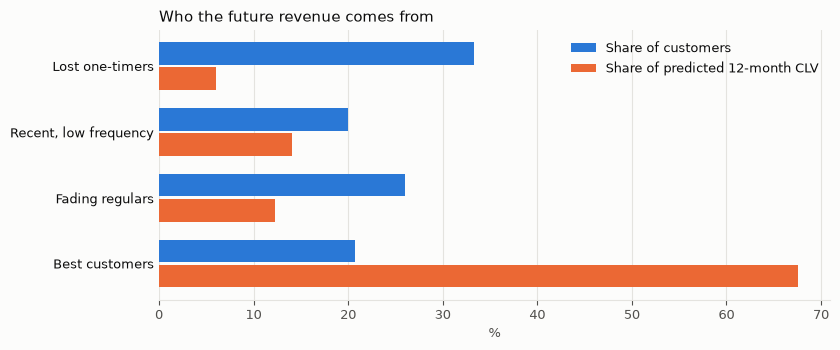

In [18]:
order = by_cluster.index[::-1]
y = np.arange(len(order))
height = 0.38

fig, ax = plt.subplots(figsize=(8.5, 3.6), facecolor=SURFACE)
ax.barh(y + height / 2, by_cluster.loc[order, "share_of_customers"] * 100, height=height - 0.04,
        color=BLUE, label="Share of customers")
ax.barh(y - height / 2, by_cluster.loc[order, "share_of_clv"] * 100, height=height - 0.04,
        color=ORANGE, label="Share of predicted 12-month CLV")
ax.set_yticks(y, order)
ax.set_xlabel("%", color=MUTED, fontsize=9)
ax.set_title("Who the future revenue comes from", loc="left", color=TEXT, fontsize=11)
style_axis(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", colors=TEXT, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9, labelcolor=TEXT)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_clv_by_cluster.png", dpi=150, facecolor=SURFACE)
plt.show()

## How the business can use the CLV

- **Set a budget per customer.** A win-back or loyalty action should cost less than the value it protects,
  so the CLV is an upper bound on what to spend on each customer.
- **Prioritise inside a segment.** Within *Fading regulars* or *At risk*, contacting first the customers
  with the highest CLV and a probability of being alive that is not yet near zero gives the best return.
- **Spot false friends.** Customers like 17850 look valuable in the totals but are probably gone: spending
  on them as if they were active customers would be wasted.

## Save the CLV table

In [19]:
result.to_parquet(PROCESSED_DIR / "clv.parquet")
print(f"Saved {len(result):,} customers to {PROCESSED_DIR.name}/clv.parquet")

Saved 5,839 customers to processed/clv.parquet


## Summary

| Choice | Decision | Reason |
|---|---|---|
| Purchase unit | One purchase per customer and day | BG/NBD counts purchase occasions |
| Monetary | Gross revenue | Gamma-Gamma needs positive values; unpaired returns are about 1% of revenue |
| Time unit | Weeks | Same predictions as days, more stable optimisation |
| Validation | 18 months calibration, 6 months holdout | With 12 months the dropout parameters are not identifiable |
| Baseline | Past repeat-purchase rate continues | Simplest forecast a business would make |
| BG/NBD vs MBG/NBD | BG/NBD, P(alive) not used for one-time buyers | Same accuracy; BG/NBD assumes one-time buyers are alive |
| Gamma-Gamma | Checked independence of frequency and value | Weak correlation, assumption acceptable |
| CLV | 12 months, 1% monthly discount, revenue not profit | No margin data |

**Limitations:** no seasonality (the holdout revenue is underestimated because pre-Christmas purchases are
larger), CLV of one-time buyers is essentially a population average, and new customers acquired in the
future are not part of it.